
               STRATEGIC RESOURCE PLANNING & ML RISK REPORT               

[1] DATASET & MACHINE LEARNING MODEL SUMMARY
--------------------------------------------------------------------------------
  • Total Backlog Tasks Analyzed  : 2,677
  • Total Technicians Evaluated   : 1,430
  • Baseline Skill Investment Cost: $175.00 per intervention
  • Risk Model Architecture       : Gradient Boosting Classifier (GBM)
  • Model Predictive ROC-AUC Score: 0.7494
  • High-Risk Backlog Tasks (>50%): 140 tasks

[2] FINANCIAL & OPTIMIZATION PERFORMANCE (BUDGET vs SAVINGS)
--------------------------------------------------------------------------------
  • Total Operational Budget Cap  : $20,000.00
  • Total Investment Capital Spent: $20,000.00 (100.0% budget utilization)
  • Total Expected Penalty Saved  : $366,509.13
  • Net Financial Value Add       : $346,509.13
  • Projected Return on Investment: 1,732.55%

[3] TARGETED VS UNTARGETED TASK PROFILES
-------------------------------------------

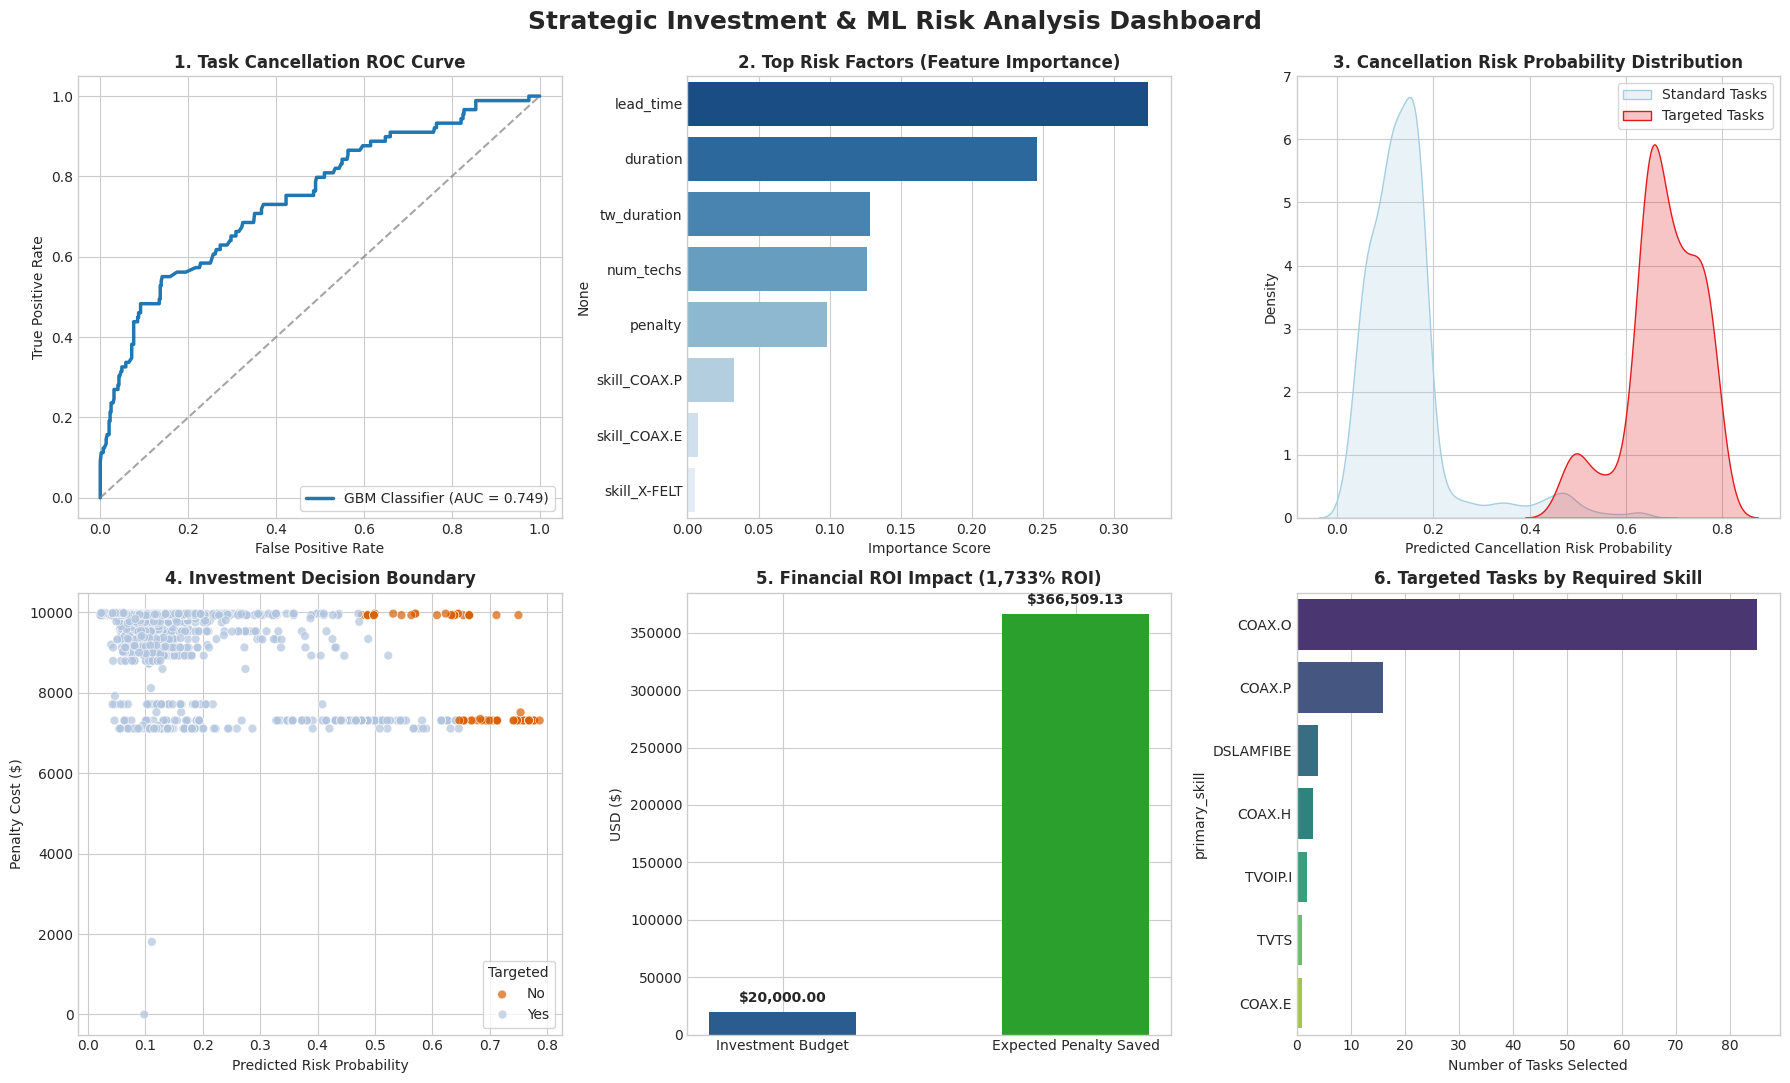

In [5]:
import re
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.optimize import linprog


plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'




def parse_investment_config(filepath):
    config = {'skill_cost': 175.0, 'skill_groups': {}}
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if "Skill investment cost:" in line:
                config['skill_cost'] = float(line.split(":")[1].strip())
            elif "Skill investment group:" in line:
                match = re.search(r"Skill investment group:\s*(\d+):\s*Set\(\[(.*?)\]\)", line)
                if match:
                    group_id = int(match.group(1))
                    raw_skills = match.group(2)
                    skills = [s.strip().replace('"', '') for s in raw_skills.split(',') if s.strip()]
                    config['skill_groups'][group_id] = skills
    return config

def parse_tasks_dataset(filepath):
    tasks = []
    with open(filepath, 'r') as f:
        for line in f:
            if not line.startswith("Task id"):
                continue
            tid = int(re.search(r"Task id (\d+)", line).group(1))
            skills_raw = re.findall(r'skills \[(.*?)\]', line)[0]
            skills = [s.strip().replace('"', '') for s in skills_raw.split(',') if s.strip()]
            duration = int(re.search(r"duration (\d+)", line).group(1))

            tw = re.findall(r'time window \[(.*?), (.*?)\]', line)[0]
            tw_start, tw_end = datetime.fromisoformat(tw[0]), datetime.fromisoformat(tw[1])
            tw_duration = (tw_end - tw_start).total_seconds() / 60.0

            priority = int(re.search(r"priority (\d+)", line).group(1))
            penalty = float(re.search(r"penalty ([\d\.]+)", line).group(1))

            created_str = re.search(r"created ([\d\-T:]+)", line).group(1)
            created = datetime.fromisoformat(created_str)
            lead_time = (tw_start - created).total_seconds() / 3600.0

            cancelled = re.search(r"cancelled (true|false)", line).group(1) == "true"
            tech_match = re.search(r"relevant technician ids \[(.*?)\]", line)
            num_techs = len(tech_match.group(1).split(',')) if (tech_match and tech_match.group(1).strip()) else 0

            tasks.append({
                'task_id': tid,
                'primary_skill': skills[0] if skills else 'None',
                'skills': skills,
                'num_skills': len(skills),
                'duration': duration,
                'tw_duration': tw_duration,
                'priority': priority,
                'penalty': penalty,
                'lead_time': lead_time,
                'num_techs': num_techs,
                'cancelled': int(cancelled)
            })
    return pd.DataFrame(tasks)

def parse_technicians_dataset(filepath):
    techs = []
    with open(filepath, 'r') as f:
        for line in f:
            if not line.startswith("Technician id"):
                continue
            tid = int(re.search(r"Technician id (\d+)", line).group(1))
            skills_raw = re.findall(r'skills \[(.*?)\]', line)[0]
            skills = [s.strip().replace('"', '') for s in skills_raw.split(',') if s.strip()]
            inv_opt = re.search(r"investment option (true|false)", line).group(1) == "true"
            techs.append({'tech_id': tid, 'skills': skills, 'can_invest': inv_opt})
    return pd.DataFrame(techs)


inv_config = parse_investment_config('TDCData_investment.txt')
df_tasks = parse_tasks_dataset('Tasks.txt')
df_techs = parse_technicians_dataset('Technicians.txt')




mlb = MultiLabelBinarizer()
skills_encoded = mlb.fit_transform(df_tasks['skills'])
skills_df = pd.DataFrame(skills_encoded, columns=[f"skill_{s}" for s in mlb.classes_])

feature_cols = ['duration', 'tw_duration', 'priority', 'penalty', 'lead_time', 'num_techs', 'num_skills']
X = pd.concat([df_tasks[feature_cols], skills_df], axis=1)
y = df_tasks['cancelled']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
clf.fit(X_train, y_train)

y_pred_proba = clf.predict_proba(X_test)[:, 1]
auc_val = roc_auc_score(y_test, y_pred_proba)

df_tasks['predicted_risk'] = clf.predict_proba(X)[:, 1]
df_tasks['expected_loss'] = df_tasks['predicted_risk'] * df_tasks['penalty']




STRATEGIC_BUDGET = 20000.0
skill_unit_cost = inv_config['skill_cost']

df_tasks['intervention_cost'] = skill_unit_cost
df_tasks['expected_saved_penalty'] = df_tasks['expected_loss'] * 0.60

n_tasks = len(df_tasks)
c = -df_tasks['expected_saved_penalty'].values
A_ub = [df_tasks['intervention_cost'].values]
b_ub = [STRATEGIC_BUDGET]
bounds = [(0, 1) for _ in range(n_tasks)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
df_tasks['is_targeted'] = res.x > 0.5


total_spent = np.sum(res.x * df_tasks['intervention_cost'].values)
total_saved = -res.fun
net_benefit = total_saved - total_spent
roi = (net_benefit / total_spent) * 100 if total_spent > 0 else 0.0




targeted_df = df_tasks[df_tasks['is_targeted']].copy()
non_targeted_df = df_tasks[~df_tasks['is_targeted']].copy()

print("\n" + "="*80)
print("               STRATEGIC RESOURCE PLANNING & ML RISK REPORT               ")
print("="*80)

print("\n[1] DATASET & MACHINE LEARNING MODEL SUMMARY")
print("-" * 80)
print(f"  • Total Backlog Tasks Analyzed  : {len(df_tasks):,}")
print(f"  • Total Technicians Evaluated   : {len(df_techs):,}")
print(f"  • Baseline Skill Investment Cost: ${skill_unit_cost:,.2f} per intervention")
print(f"  • Risk Model Architecture       : Gradient Boosting Classifier (GBM)")
print(f"  • Model Predictive ROC-AUC Score: {auc_val:.4f}")
print(f"  • High-Risk Backlog Tasks (>50%): {(df_tasks['predicted_risk'] > 0.5).sum():,} tasks")

print("\n[2] FINANCIAL & OPTIMIZATION PERFORMANCE (BUDGET vs SAVINGS)")
print("-" * 80)
print(f"  • Total Operational Budget Cap  : ${STRATEGIC_BUDGET:,.2f}")
print(f"  • Total Investment Capital Spent: ${total_spent:,.2f} ({total_spent/STRATEGIC_BUDGET*100:.1f}% budget utilization)")
print(f"  • Total Expected Penalty Saved  : ${total_saved:,.2f}")
print(f"  • Net Financial Value Add       : ${net_benefit:,.2f}")
print(f"  • Projected Return on Investment: {roi:,.2f}%")

print("\n[3] TARGETED VS UNTARGETED TASK PROFILES")
print("-" * 80)
print(f"  Metric                      | Targeted Tasks (N={len(targeted_df)}) | Non-Targeted Tasks (N={len(non_targeted_df)})")
print(f"  ----------------------------+-----------------------+-------------------------")
print(f"  Avg Predicted Risk Prob     | {targeted_df['predicted_risk'].mean()*100:21.1f}% | {non_targeted_df['predicted_risk'].mean()*100:23.1f}%")
print(f"  Avg Base Penalty Value ($)  | ${targeted_df['penalty'].mean():20,.2f} | ${non_targeted_df['penalty'].mean():22,.2f}")
print(f"  Avg Expected Loss Saved ($) | ${targeted_df['expected_saved_penalty'].mean():20,.2f} | $                    0.00")

print("\n[4] SKILL ALLOCATION BREAKDOWN (TOP CAPITAL RECIPIENTS)")
print("-" * 80)
skill_summary = targeted_df.groupby('primary_skill').agg(
    tasks_selected=('task_id', 'count'),
    total_cost=('intervention_cost', 'sum'),
    total_savings=('expected_saved_penalty', 'sum')
).reset_index()
skill_summary['roi'] = ((skill_summary['total_savings'] - skill_summary['total_cost']) / skill_summary['total_cost']) * 100
skill_summary = skill_summary.sort_values(by='total_savings', ascending=False).head(5)

print(f"  {'Skill Category':<15} | {'Tasks':<8} | {'Capital Spent':<14} | {'Expected Savings':<18} | {'Skill ROI':<10}")
print("  " + "-"*75)
for _, row in skill_summary.iterrows():
    print(f"  {row['primary_skill']:<15} | {row['tasks_selected']:<8} | ${row['total_cost']:<13,.2f} | ${row['total_savings']:<17,.2f} | {row['roi']:,.0f}%")

print("\n[5] TOP 5 HIGH-PRIORITY TASKS TARGETED FOR IMMEDIATE ACTION")
print("-" * 80)
top_5_tasks = targeted_df.sort_values(by='expected_saved_penalty', ascending=False).head(5)
print(f"  {'Task ID':<8} | {'Primary Skill':<14} | {'Priority':<8} | {'Penalty ($)':<12} | {'Risk Prob':<10} | {'Saved ($)':<12}")
print("  " + "-"*75)
for _, row in top_5_tasks.iterrows():
    print(f"  {row['task_id']:<8} | {row['primary_skill']:<14} | {row['priority']:<8} | ${row['penalty']:<11,.2f} | {row['predicted_risk']*100:<9.1f}% | ${row['expected_saved_penalty']:<11,.2f}")

print("="*80 + "\n")




fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Strategic Investment & ML Risk Analysis Dashboard', fontsize=18, fontweight='bold', y=0.98)


fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0, 0].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'GBM Classifier (AUC = {auc_val:.3f})')
axes[0, 0].plot([0, 1], [0, 1], color='gray', linestyle='--', alpha=0.7)
axes[0, 0].set_title('1. Task Cancellation ROC Curve', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].legend(loc='lower right', frameon=True)


importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
sns.barplot(
    x=importances.values,
    y=importances.index,
    hue=importances.index,
    ax=axes[0, 1],
    palette='Blues_r'
)
if axes[0, 1].get_legend():
    axes[0, 1].get_legend().remove()
axes[0, 1].set_title('2. Top Risk Factors (Feature Importance)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Importance Score')


sns.kdeplot(data=df_tasks[~df_tasks['is_targeted']]['predicted_risk'], ax=axes[0, 2], fill=True, color='#a6cee3', label='Standard Tasks')
sns.kdeplot(data=df_tasks[df_tasks['is_targeted']]['predicted_risk'], ax=axes[0, 2], fill=True, color='#e31a1c', label='Targeted Tasks')
axes[0, 2].set_title('3. Cancellation Risk Probability Distribution', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Predicted Cancellation Risk Probability')
axes[0, 2].set_ylabel('Density')
axes[0, 2].legend(frameon=True)


sns.scatterplot(
    data=df_tasks,
    x='predicted_risk',
    y='penalty',
    hue='is_targeted',
    palette={False: '#b0c4de', True: '#d95f02'},
    alpha=0.7,
    s=40,
    ax=axes[1, 0]
)
axes[1, 0].set_title('4. Investment Decision Boundary', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Predicted Risk Probability')
axes[1, 0].set_ylabel('Penalty Cost ($)')
axes[1, 0].legend(title='Targeted', labels=['No', 'Yes'], frameon=True)


bars = axes[1, 1].bar(['Investment Budget', 'Expected Penalty Saved'], [total_spent, total_saved], color=['#2b5c8f', '#2ca02c'], width=0.5)
axes[1, 1].set_title(f'5. Financial ROI Impact ({roi:,.0f}% ROI)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('USD ($)')
for bar in bars:
    height = bar.get_height()
    axes[1, 1].annotate(f'${height:,.2f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 5), textcoords="offset points",
                        ha='center', va='bottom', fontweight='bold')


top_skills = df_tasks[df_tasks['is_targeted']]['primary_skill'].value_counts().head(7)
sns.barplot(
    x=top_skills.values,
    y=top_skills.index,
    hue=top_skills.index,
    ax=axes[1, 2],
    palette='viridis'
)
if axes[1, 2].get_legend():
    axes[1, 2].get_legend().remove()
axes[1, 2].set_title('6. Targeted Tasks by Required Skill', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Number of Tasks Selected')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()